<b><font size="6" color="#E8800A">The dataset and business need</font></b><br>

We are aiming to predict whether a customer will make another purchase within 90 days of the current purchase. The company could use these predictions to prioritize customer follow-up. Each row represents a purchase occasion, so the same customer can appear several times.

| Column | Type | Note |
|---|---|---|
| `ID` | Identifier | Index, not a feature |
| `customer_id` | Identifier | Kept out of the model; used to group the split |
| `repeat_purchase_90d` | Target | Binary |
| `random_noise` | Numeric | Additional numerical field whose predictive usefulness will be assessed later |
| `document_series` | Categorical | 3 levels |
| `warehouse` | Categorical | 2 levels |
| `invoice_count_current_purchase` | Numeric count | Values 1-5 |
| `N_ Detalhes` | Numeric count | |
| `prior_purchase_count` | Numeric count | |
| `purchase_count_30d` | Numeric count | Check window direction |
| `purchase_count_90d` | Numeric count | Check window direction |
| `purchase_count_180d` | Numeric count | Check window direction |
| `purchase_count_365d` | Numeric count | Check window direction |
| `days_since_previous_purchase` | Numeric | Blank = first purchase? |
| `customer_tenure_days` | Numeric | |
| `prior_mean_gap_days` | Numeric | |
| `prior_std_gap_days` | Numeric | |
| `Total a Pagar` | Numeric | |
| `Total Bruto` | Numeric | Likely correlated with `Total a Pagar` |
| `Total Liquido` | Numeric | Likely correlated with `Total a Pagar` |
| `Total Imp_` | Numeric | |
| `Total Portes` | Numeric | |
| `Total Desc_ Global` | Numeric | |
| `Total Desc_ Linha` | Numeric | |
| `Custo` | Numeric | |
| `prior_total_spend` | Numeric | |
| `prior_mean_purchase_value` | Numeric | 16 negatives |
| `prior_std_purchase_value` | Numeric | |
| `prior_min_purchase_value` | Numeric | |
| `prior_max_purchase_value` | Numeric | |
| `spend_30d` | Numeric | Check window direction |
| `spend_90d` | Numeric | Check window direction |
| `spend_180d` | Numeric | Check window direction |
| `spend_365d` | Numeric | 15 negatives; check window direction |

<b><font size="6" color="#E8800A">Import</font></b><br>

In [1]:
import sys
import warnings
from collections import namedtuple
from functools import partial
from pathlib import Path

# course_helpers.py sits in this folder, next to the notebook.
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
from math import ceil
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

In [2]:
train_df = pd.read_csv("../data/train.csv", index_col="ID")
clients_df = pd.read_csv("../data/clientes.csv", index_col="customer_id")
test_df = pd.read_csv("../data/test.csv", index_col="ID")

<b><font size="6" color="#E8800A">Data Exploration</font></b><br>

This section is dedicated to the exploratory analysis of the dataset. Starting with analyzing the training data and the type of each column.

In [3]:
train_df.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [4]:
train_df.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

We can see several monetary columns and purchase count columns, all numeric. The column `purchase_date` is a str type, but we want it to be a date type. There are also 5 categorical columns and one identifier (`customer_id`).

For starters, we put the correct type in the date columns, and separate our columns into five different categories: identifiers, target, date, numeric and categorical.

In [5]:
train_df["purchase_date"] = pd.to_datetime(train_df["purchase_date"], format="%Y-%m-%d")

In [6]:
test_dates = pd.to_datetime(test_df["purchase_date"])

pd.DataFrame({
    "dataset": ["Train", "Test"],
    "first_purchase": [
        train_df["purchase_date"].min(),
        test_dates.min()
    ],
    "last_purchase": [
        train_df["purchase_date"].max(),
        test_dates.max()
    ]
})

,dataset,first_purchase,last_purchase
0,Train,2015-07-11,2025-02-15
1,Test,2025-05-24,2026-10-06


The test set contains later purchases than the training set does. We should take this into account when deciding how to evaluate our models.

In [7]:
identifiers = ["customer_id"]
target = "repeat_purchase_90d"
date = ["purchase_date"]

numeric = [c for c in train_df.columns
           if c not in identifiers + [target] + date
           and pd.api.types.is_numeric_dtype(train_df[c])]
categorical = [c for c in train_df.columns
               if c not in identifiers + [target] + date + numeric]

In the next cell, we checked if there were any numerical columns with low cardinality (less than 10 unique values) and how many levels each categorical value has.

In [8]:
low_cardinality = {c: train_df[c].nunique() for c in numeric if train_df[c].nunique() <= 10}
levels = train_df[categorical].nunique().sort_values(ascending=False)
print(f"Numeric columns with low cardinality: {low_cardinality}")

roles = pd.Series({
    "identifiers": f"{len(identifiers)} {identifiers}",
    "numeric": f"{len(numeric)}, of which low-cardinality: {low_cardinality}",
    "categorical": f"{len(categorical)}, holding {int(levels.sum())} levels"
                   f" -> {int(levels.sum())} columns once encoded",
    "target": target,
    "'customer_id' passes select_dtypes('number')":
        "customer_id" in train_df.select_dtypes("number").columns,
})
print(roles.to_frame("what each group holds").to_string())
levels.to_frame("levels")

Numeric columns with low cardinality: {'invoice_count_current_purchase': 5}
                                                                                            what each group holds
identifiers                                                                                     1 ['customer_id']
numeric                                       29, of which low-cardinality: {'invoice_count_current_purchase': 5}
categorical                                                     6, holding 108 levels -> 108 columns once encoded
target                                                                                        repeat_purchase_90d
'customer_id' passes select_dtypes('number')                                                                 True


,levels
transport_method,80
payment_type,9
salesperson,9
commercial_zone,5
document_series,3
warehouse,2


In [9]:
train_df.duplicated().sum()

np.int64(10)

<b><font size="5" color="#E8800A">The identifier</font></b><br>

In [10]:
per_customer = train_df.groupby("customer_id").size()
print(f"\nsurplus rows on 'customer_id': {train_df.duplicated(subset='customer_id').sum()}")
print(f"rows sharing a 'customer_id': {per_customer[per_customer > 1].sum()}"
      f" across {(per_customer > 1).sum()} customers")
print("records per customer:", per_customer.value_counts().to_dict())
print("unique customers:", train_df['customer_id'].nunique())


surplus rows on 'customer_id': 5924
rows sharing a 'customer_id': 6377 across 453 customers
records per customer: {1: 157, 2: 84, 3: 49, 4: 47, 6: 25, 5: 23, 7: 21, 10: 14, 15: 13, 9: 13, 11: 12, 8: 11, 13: 10, 21: 9, 14: 8, 18: 8, 24: 7, 17: 7, 16: 6, 29: 5, 26: 5, 22: 4, 12: 4, 50: 4, 19: 4, 35: 3, 31: 3, 23: 3, 30: 3, 28: 3, 89: 2, 42: 2, 54: 2, 41: 2, 63: 2, 51: 2, 32: 2, 37: 2, 27: 2, 36: 2, 277: 1, 43: 1, 38: 1, 25: 1, 74: 1, 81: 1, 203: 1, 33: 1, 49: 1, 59: 1, 39: 1, 67: 1, 73: 1, 48: 1, 53: 1, 66: 1, 62: 1, 55: 1, 80: 1, 112: 1, 60: 1, 47: 1, 40: 1, 56: 1, 20: 1}
unique customers: 610


There are 610 different customers in the dataset, with 453 of them having multiple purchases. Having the same customer in both sides of the split favours the score.

<b><font size="5" color="#E8800A">Missing and impossible values</font></b><br>

First, we wanted to know how many missing values we had in our data and how they are distributed.

In [11]:
rows_with_null = train_df.isna().any(axis=1)
per_column = train_df.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(train_df):,}"
                        f" ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {train_df.shape[1]}",
    "null cells": f"{train_df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"2,605 of 6,534 (39.87%)"
columns with a null,36 of 38
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


Almost 40% of all rows have missing values, with a total of 9818 cells missing. Only two columns don't have any null values. Some missing values have to do with the fact that some customers have little or no purchase history. We will look into this and the rows with missing transaction information later on.

In [12]:
train_df.isna().sum()[lambda s: s == 0]

repeat_purchase_90d    0
customer_id            0
dtype: int64

Only the identifier and target columns have 0 missing values.

Next, we looked for negative values.

In [13]:
cols = numeric
check = pd.DataFrame({
    "min": train_df[cols].min(),
    "n_negative": (train_df[cols] < 0).sum()
})
check[check["n_negative"] > 0]

,min,n_negative
days_since_previous_purchase,-4.000000,16
prior_mean_purchase_value,-2478.658478,16
prior_mean_gap_days,-4.000000,16
spend_365d,-159115.175535,15
random_noise,-3.529210,3357


There are only four columns with negative values. Two of these columns have -4 as their minimum value so next we analysed the distinct negative values of these columns to check whether these were filler values for when we don't have data or if they were errors.

In [14]:
for c in ["days_since_previous_purchase", "prior_mean_gap_days", "prior_mean_purchase_value", "spend_365d"]:
    print(train_df.loc[train_df[c] < 0, c].value_counts())

days_since_previous_purchase
-4.0    16
Name: count, dtype: int64
prior_mean_gap_days
-4.0    16
Name: count, dtype: int64
prior_mean_purchase_value
-110.147097     1
-409.791667     1
-218.266392     1
-417.917143     1
-779.030000     1
-212.360622     1
-366.120000     1
-2478.658478    1
-693.010000     1
-757.480000     1
-305.930000     1
-504.580000     1
-357.193750     1
-162.482308     1
-883.510000     1
-885.097111     1
Name: count, dtype: int64
spend_365d
-3456.320000      1
-1230.720000      1
-167.180000       1
-753.510000       1
-2648.440000      1
-2169.910000      1
-1443.640000      1
-5133.040000      1
-14740.290000     1
-4196.900000      1
-1620.830000      1
-6795.470000      1
-159115.175535    1
-295.380000       1
-12638.050000     1
Name: count, dtype: int64


While in prior_mean_purchase_value and spend_365d all negative values are different, in the days_since_previous_purchase and prior_mean_gap_days columns all negative values are -4. This number appears to be a "filler" value for when we don't have information.

<b><font size="5" color="#E8800A">Numeric columns</font></b><br>

The next cells are dedicated to the exploratory analysis of the numeric columns, starting with descriptive statistics for each one of them.

In [15]:
train_df.describe().T

,count,mean,min,25%,50%,75%,max,std
Total a Pagar,6469.0,925.556262,0.93,188.92,476.74,1087.67,22297.21,1334.997733
Total Bruto,6469.0,886.152705,0.83,175.74,445.74,1036.7,21578.28,1327.641086
Total Liquido,6469.0,773.336384,0.76,154.38,389.91,903.37,18127.81,1136.355723
Total Imp_,6469.0,152.219878,0.0,29.93,79.74,184.84,4169.4,225.262375
Total Portes,6469.0,1.151427,0.0,0.0,0.0,0.0,181.06,5.844091
Total Desc_ Global,6469.0,0.349907,0.0,0.0,0.0,0.0,218.49,5.116564
Total Desc_ Linha,6469.0,112.466414,0.0,0.0,13.13,92.28,4103.44,289.986307
Custo,6469.0,328.16504,0.0,49.05,152.54,396.061499,7427.400583,519.507218
N_ Detalhes,6469.0,21.524501,1.0,4.0,11.0,29.0,423.0,27.713419
invoice_count_current_purchase,6469.0,1.066007,1.0,1.0,1.0,1.0,5.0,0.310807


Both prior_mean_purchase_value and spend_365d reach 1 billion, which is unusually high and needs checking. For `Total a Pagar`, the mean is about 926 while the median is about 477, which makes us think that some large purchases are pulling the average up. Total Portes and Total Desc_ Global both have a median of zero, showing that these amounts are zero for many purchases.

Below we calculated some metrics such as skew and % of zeros to determine the asymmetry of the variables. To complement this, we made histograms of each column.

In [16]:
summary = train_df[numeric].describe().T
shape = summary.copy()
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = train_df[numeric].skew()
shape["% zeros"] = 100 * (train_df[numeric] == 0).mean()

shape[["mean", "50%", "mean/median", "skew", "% zeros"]].round(2)

,mean,50%,mean/median,skew,% zeros
Total a Pagar,925.56,476.74,1.94,4.21,0.00
Total Bruto,886.15,445.74,1.99,4.31,0.00
Total Liquido,773.34,389.91,1.98,4.15,0.00
Total Imp_,152.22,79.74,1.91,4.84,3.26
Total Portes,1.15,0.00,NaN,19.55,82.89
Total Desc_ Global,0.35,0.00,NaN,27.46,97.32
Total Desc_ Linha,112.47,13.13,8.57,5.92,37.36
Custo,328.17,152.54,2.15,4.61,7.44
N_ Detalhes,21.52,11.00,1.96,2.98,0.00
invoice_count_current_purchase,1.07,1.00,1.07,6.44,0.00


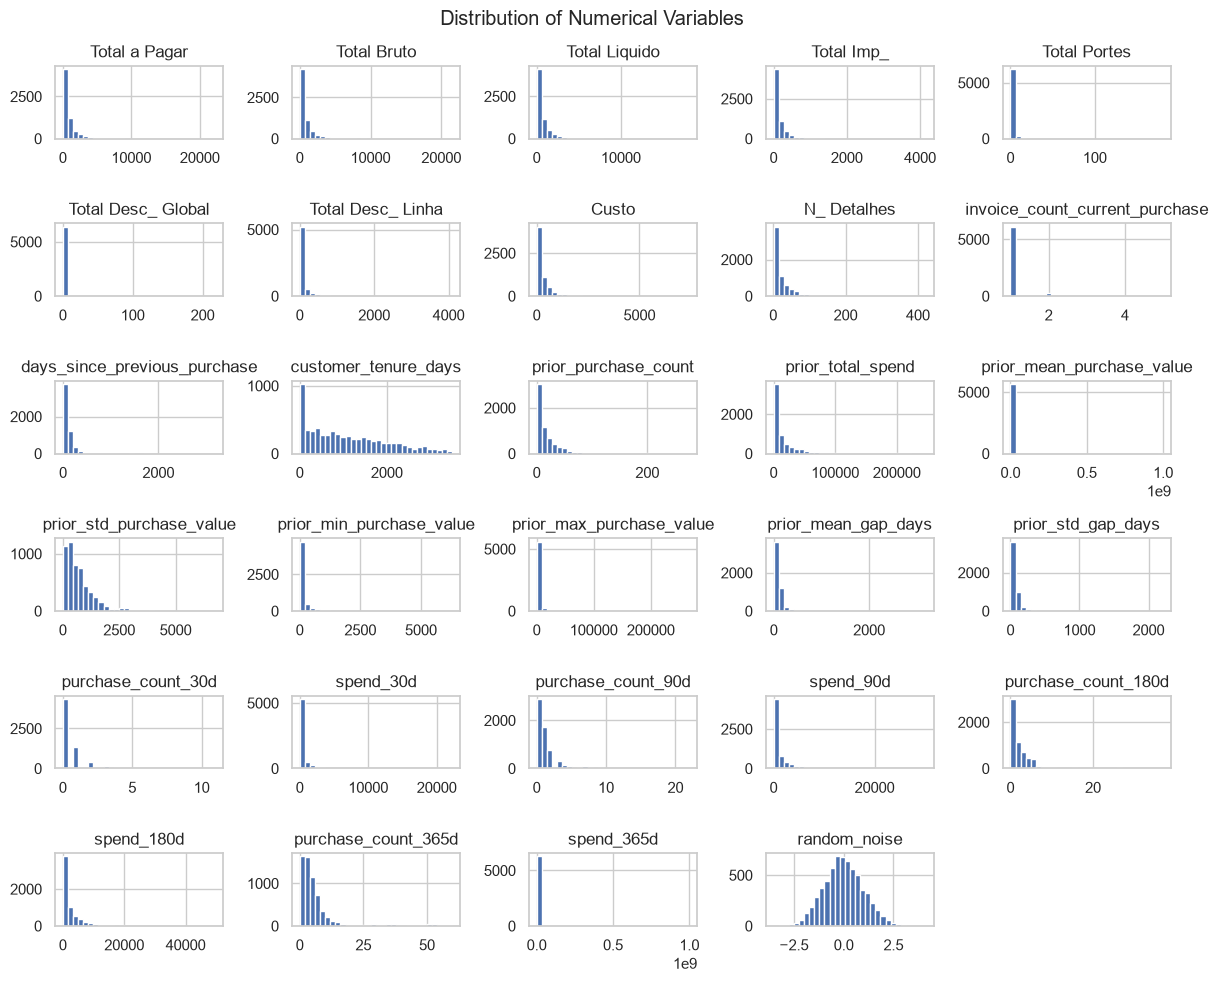

In [17]:
train_df[numeric].hist(figsize=(12, 10), bins=30)
plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

From this analysis it is visible that the numeric columns are highly skewed to the right. We also have some columns with high percentage of zeros, the worst column being Total Desc_ Global with 97.32% zeros.

<b><font size="5" color="#E8800A">Categorical columns</font></b><br>

Next we do a similar exploratory data analysis, but for the categorical columns, using descriptive statistics and bar charts.

In [18]:
train_df.describe(include = 'str')

,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series
count,6274,6275,6469,6273,6274,6469
unique,9,9,5,80,2,3
top,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2
freq,4565,4054,6260,1119,6253,2738


Since `transport_method` has 80 different levels, we decided not to include the column in the graphical representation.

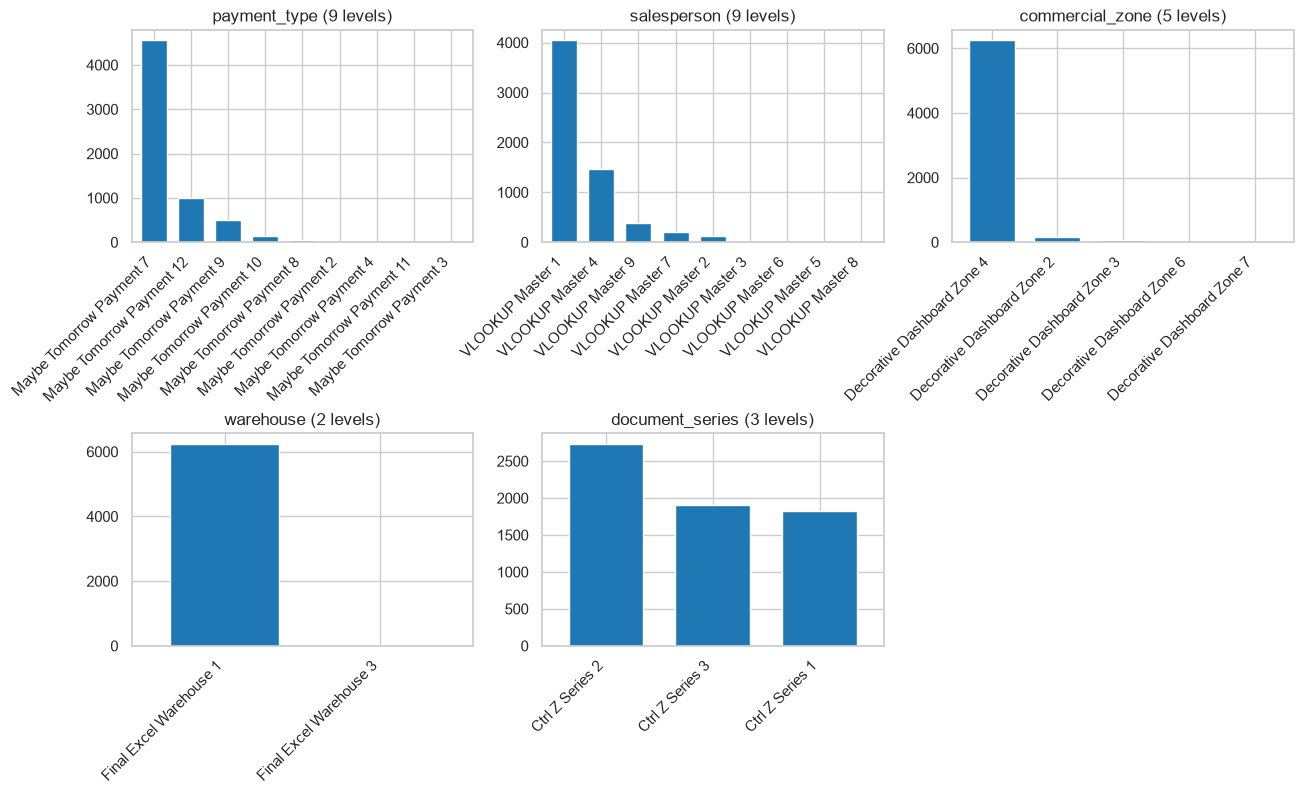

In [19]:
plot_columns = [c for c in categorical if c != "transport_method"]

n_cols = ceil(len(plot_columns) / 2)
fig, axes = plt.subplots(2, n_cols, figsize=(5 * n_cols, 8))

for ax, feat in zip(axes.flatten(), plot_columns):
    counts = train_df[feat].value_counts()
    counts.plot.bar(ax=ax, width=.7, color="#1F77B4")
    ax.set_title(f"{feat} ({len(counts)} levels)")
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

for ax in axes.flatten()[len(plot_columns):]:
    ax.set_visible(False)

plt.subplots_adjust(hspace=0.9)
plt.show()

The categorical columns are highly concentrated. `commercial_zone` and `warehouse` are almost constant (one level holds nearly all rows), `payment_type` and `salesperson` are dominated by one level, and only `document_series` is balanced across its three levels.

In [20]:
train_df.groupby("payment_type",dropna=False)["repeat_purchase_90d"].agg(
    rows="size",
    repeat_rate="mean"
).sort_values("rows",ascending=False)

,rows,repeat_rate
payment_type,,
Maybe Tomorrow Payment 7,4565,0.527273
Maybe Tomorrow Payment 12,991,0.542886
Maybe Tomorrow Payment 9,502,0.950199
NaN,260,0.550000
Maybe Tomorrow Payment 10,134,0.402985
Maybe Tomorrow Payment 8,40,0.325000
Maybe Tomorrow Payment 2,21,0.523810
Maybe Tomorrow Payment 4,9,0.444444
Maybe Tomorrow Payment 11,8,0.625000


With this we are examining the repeat-purchase rate within each payment category, as well as the number of observations of that rate. We can see that "Maybe Tomorrow Payment 9" has a much higher repeat-purchase rate, compared with the 2 other most common payment categories.

<b><font size="5" color="#E8800A">The target</font></b><br>

Since no `repeat_purchase_90d` value is null (NA), we proceed to the analysis of the target column. The first step is to count the absolute and relative frequency of 1's and 0's. Then we compare the other features between the two classes.

In [21]:
count_target = train_df['repeat_purchase_90d'].value_counts()

target_prop = count_target.to_frame("count").assign(proportion=lambda d: d["count"] / d["count"].sum())
target_prop

,count,proportion
repeat_purchase_90d,,
1,3654,0.559229
0,2880,0.440771


55.92% of the target rows are 1 and 44.08% are 0, therefore our target column is relatively balanced.

In [22]:
train_df[numeric].groupby(train_df["repeat_purchase_90d"]).mean().round(2).T

repeat_purchase_90d,0,1
Total a Pagar,808.56,1017.58
Total Bruto,762.81,983.17
Total Liquido,680.06,846.70
Total Imp_,128.49,170.88
Total Portes,1.16,1.15
Total Desc_ Global,0.42,0.30
Total Desc_ Linha,82.33,136.17
Custo,299.83,350.45
N_ Detalhes,20.79,22.10
invoice_count_current_purchase,1.05,1.08


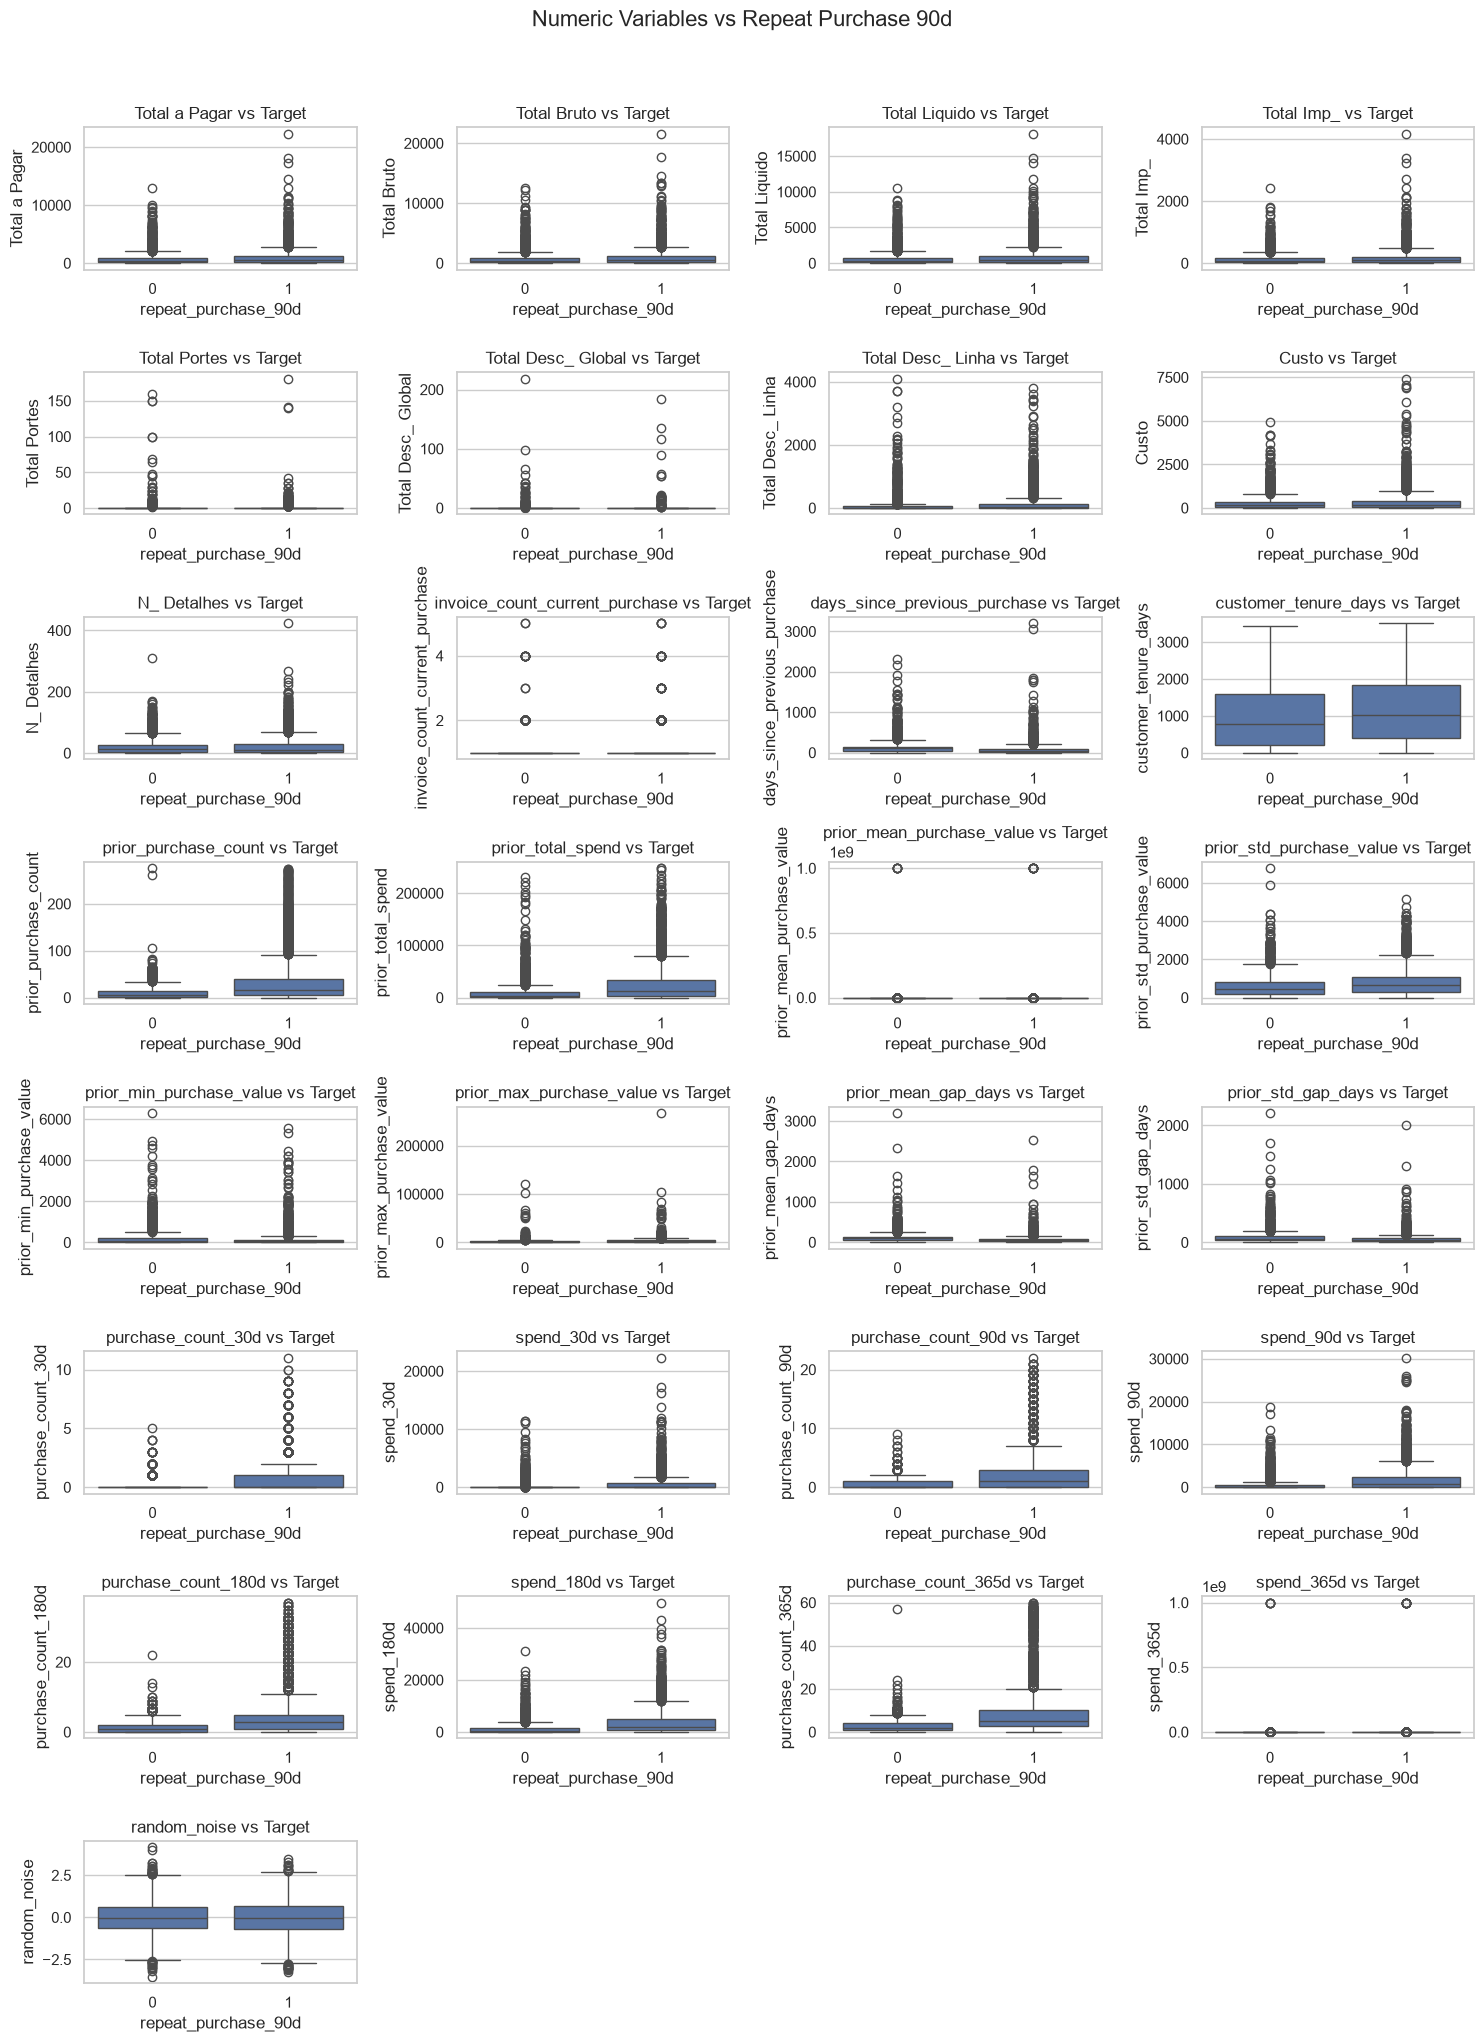

In [23]:
# Examining numerical features in relation to the target using Boxplots (checking which features are good predictors of the target)
fig, axes = plt.subplots(ceil(len(numeric) / 4), 4, figsize=(15, 20))

# Iterating each box plot and adding x='repeat_purchase_90d'
for ax, feat in zip(axes.flatten(), numeric): 
    sns.boxplot(data=train_df, x='repeat_purchase_90d', y=feat, ax=ax)
    ax.set_title(f'{feat} vs Target')

# hiding the empty graphs that would appear at the end
for ax in axes.flatten()[len(numeric):]:
    fig.delaxes(ax)

# Layout and title
plt.suptitle("Numeric Variables vs Repeat Purchase 90d", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

By looking at the boxplots and the table before, it seems that customers who buy again within 90 days tend to have more previous purchases and a shorter time since their last purchase. These patterns suggest that purchase history could help predict repeat purchases. The boxplots also show a lot of outliers in almost every variable and confirm the high proportion of zeros that we observed in the descriptive statistics of the numeric columns.

<b><font size="5" color="#E8800A">Correlation between numeric variables</font></b><br>

The cell below creates a heatmap showing the pearson correlation for every pair of numeric columns. This analysis allows us to determine if the columns have correlations between each other, which can indicate redundancy if the correlation is almost perfect. It can also show which columns better explain the target.

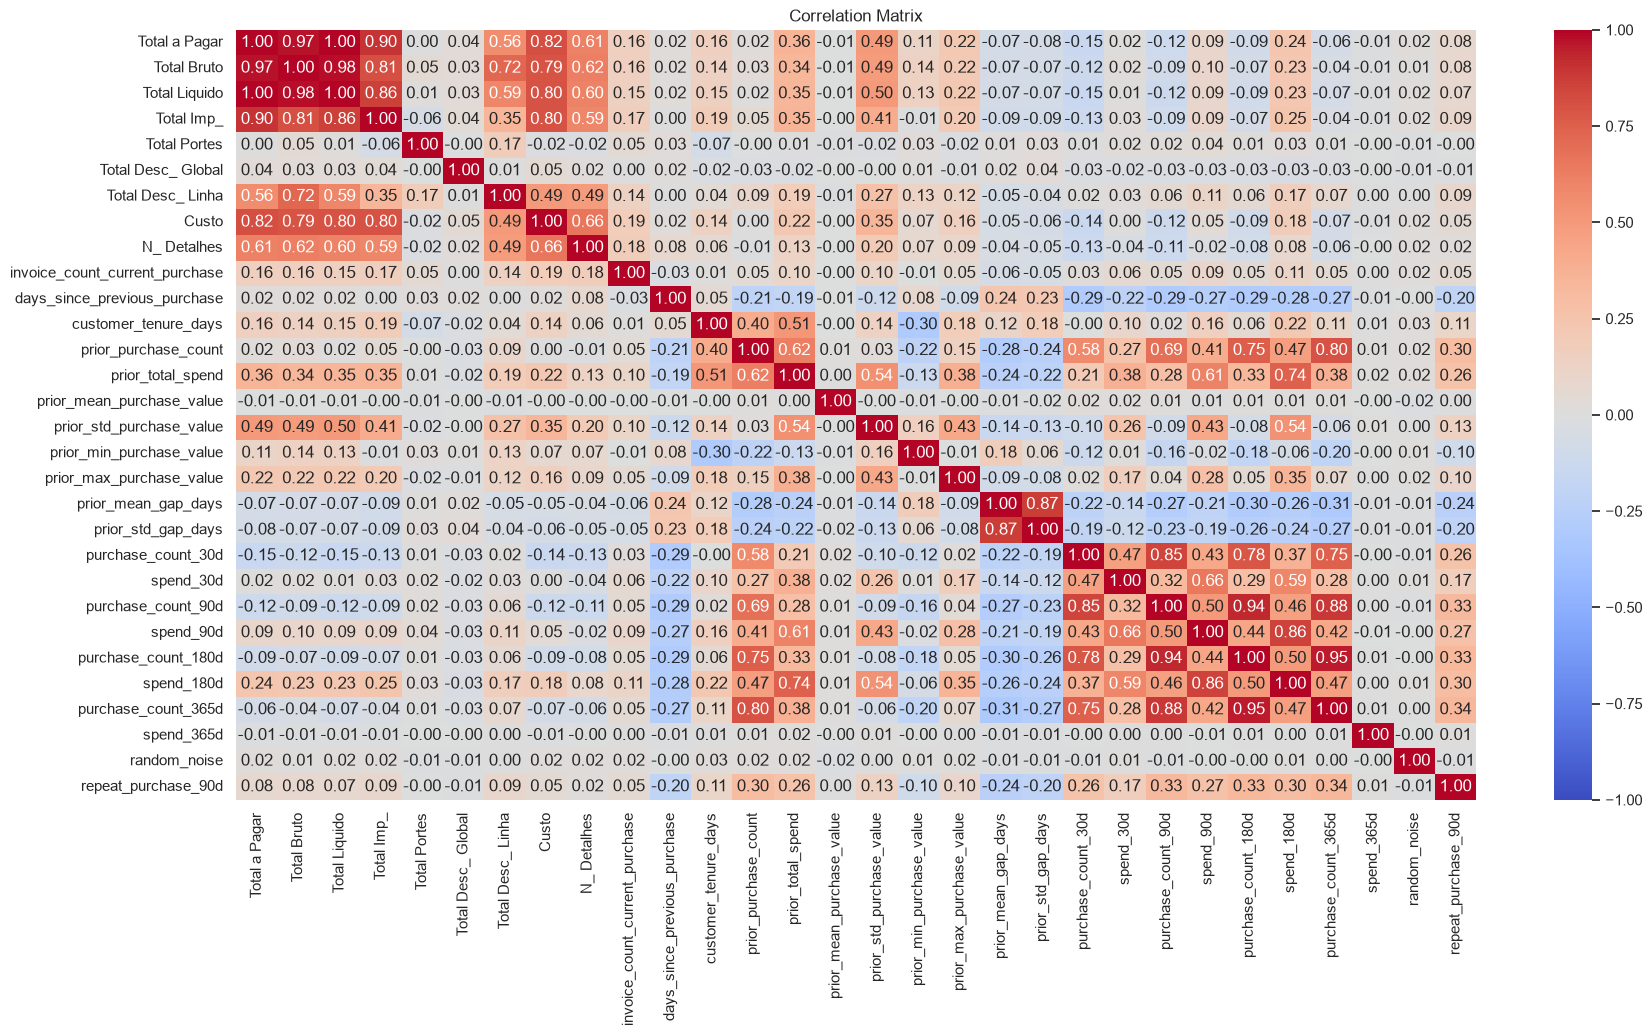

In [24]:
# multivariate relationships (Calculating Pearson's correlation coefficient between each feature)
plt.figure(figsize=(20, 10))
sns.heatmap(train_df[numeric + [target]].corr(), fmt=".2f", annot=True,
            cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation Matrix")
plt.show()

- `Total a Pagar`, `Total Bruto`, `Total Liquido` and `Total Imp_` are almost perfectly correlated (0.81 to 1), which is expected, because of the accounting identities between them.
- `purchase_count_30d`, `_90d`, `_180d` and `_365d` are also highly correlated, some of them almost perfect (0.75 to 0.95), because the count is cumulative (shorter windows are nested inside longer ones). `prior_purchase_count` also has high correlation with these columns, but not as high because it counts purchases from before 365 days.
- `spend_30d`, `spend_90d` and `spend_180d` are related to each other (0.66 to 0.86) and to `prior_total_spend` (0.61 to 0.74). `spend_365d` is the exception.
- `prior_mean_gap_days` and `prior_std_gap_days` are strongly related (0.87). Both are negatively correlated with the purchase counts (-0.21 to -0.31): customers who buy more often have shorter gaps between purchases.
- `customer_tenure_days` is moderately correlated with `prior_purchase_count` (0.40) and `prior_total_spend` (0.51), as longer-standing customers have bought more.

Invoice columns and purchase count columns seem to have similar information.

<b><font size="5" color="#E8800A">Cramer's V</font></b><br>

We used the following graph to check whether missing or invalid values are tied to particular categories, measured by Cramér's V (0 = no association, 1 = fully determined).

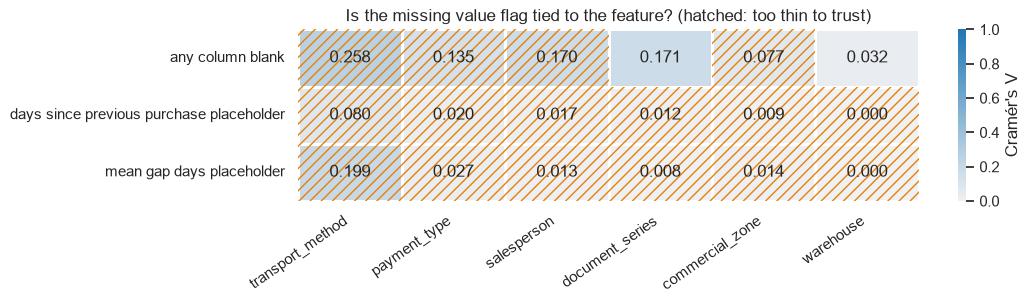

In [25]:
test_columns = [c for c in categorical if c != "purchase_date"]

days_placeholder = train_df["days_since_previous_purchase"] < 0
gap_placeholder  = train_df["prior_mean_gap_days"] < 0

missing_flags = {
    "any column blank": train_df.isna().any(axis=1),
    "days since previous purchase placeholder": days_placeholder,
    "mean gap days placeholder": gap_placeholder,
}

rows = []
for missing_source, flag in missing_flags.items():
    for column in test_columns:
        table = pd.crosstab(flag, train_df[column])
        chi2, p, _, expected = chi2_contingency(table)
        rows.append({
            "missing source": missing_source,
            "feature": column,
            "chi2": chi2,
            "Cramer's V": association(table, method="cramer", correction=True),
            "p": p,
            "min expected count": expected.min(),
        })
association_table = pd.DataFrame(rows)

strength = association_table.pivot(
    index="missing source", columns="feature", values="Cramer's V")
too_thin = association_table.pivot(
    index="missing source", columns="feature", values="min expected count") < 5
by_strength = strength.loc["days since previous purchase placeholder"].sort_values(
    ascending=False).index
strength, too_thin = strength[by_strength], too_thin[by_strength]

fig, ax = plt.subplots(figsize=(11, 3.2))
sns.heatmap(strength, vmin=0, vmax=1, annot=True, fmt=".3f", linewidths=2,
            cmap=sns.light_palette("#1F77B4", as_cmap=True),
            cbar_kws={"label": "Cramér's V"}, ax=ax)
# Hatched where the minimum expected count is under 5: that cell's colour is
# arithmetic rather than evidence, and hatching says so without hiding it.
for row, column in zip(*np.where(too_thin.values)):
    ax.add_patch(plt.Rectangle((column, row), 1, 1, fill=False, hatch="///",
                               edgecolor="#E8800A", linewidth=0))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Is the missing value flag tied to the feature? (hatched: too thin to trust)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()

In the categorical columns exploratory analysis we noticed that several levels contain very few rows, which explains why so many cells in the Cramér’s V graph are hatched (orange lines over the cells). Few observations can strongly affect the result, for this reason most of the values of this graph are unreliable. One of those unreliable values is the largest association we found (missing values by `transport_method`). 

The only reliable values are missing value and `document_series` (0.171), which makes sense according to the bar chart we saw before. However this is not a high association. `warehouse` and missing values is also reliable, but has little to no association (0.032).